In [1]:
from UMAP_utils import *

# Import data

In [2]:
path = "../data/all_MGS.csv"
df = pd.read_csv(path)

In [3]:
# Clean data
df = df.iloc[:, 2:]
df.columns = df.columns.str.strip().str.lower()
df.iloc[:, 1:9] = df.iloc[:, 1:9].apply(pd.to_numeric, errors="coerce")
df = df.dropna()

print("Number of cells is:", df.shape[0])

Number of cells is: 516


In [4]:
df.groupby(["experiment", "sample"]).size()

experiment  sample
20226       MGS1      24
            MGS2      24
            MGS3      30
            MGS4      22
            MGS5      24
            WT        23
140226      MGS1      19
            MGS2      25
            MGS3      33
            MGS4      21
            MGS5      22
            WT        45
190226      MGS1      31
            MGS2      31
            MGS3      24
            MGS4      39
            MGS5      44
            WT        35
dtype: int64

In [5]:
df.head()

,image_id,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,sample,experiment
0,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,268,6.0,2.763953,0.848528,0.875000,5.414214,45.222221,50.0,40.0,WT,20226
1,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,277,5.0,2.523133,0.848911,0.903226,5.207107,25.250000,29.0,22.0,WT,20226
2,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,320,5.0,2.523133,0.867934,1.000000,4.621320,31.743421,36.0,28.0,WT,20226
3,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,341,5.0,2.523133,0.834131,1.000000,5.207107,45.625000,51.0,40.0,WT,20226
4,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,336,4.0,2.256758,0.870250,1.000000,3.414214,34.571430,38.0,31.0,WT,20226


# UMAP

In [6]:
features = [
    "n_foci",
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
    "min_intensity",
]

# Select features
X = df[features]

# Standardize
X_scaled = StandardScaler().fit_transform(X)

# UMAP
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=42
)

X_umap = reducer.fit_transform(X_scaled)

# Create dataframe
umap_df = df.copy()

umap_df["UMAP1"] = X_umap[:, 0]
umap_df["UMAP2"] = X_umap[:, 1]

/home/lopatushka/miniconda3/envs/imagej/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


### Batch effect for all samples

In [ ]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="experiment",
    palette="Set2",
    alpha=0.7,
    s=35
)

plt.title("UMAP — Batch effects")
plt.tight_layout()
plt.show()

In [ ]:
g = sns.relplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    col="experiment",
    hue="sample",
    kind="scatter",
    palette="tab10",
    alpha=0.7,
    s=25,
    col_wrap=3,
    height=5
)

plt.show()

In [ ]:
# Remove missing values
df_clean = df.dropna(
    subset=features + ["experiment"]
).copy()

# Standardize features
X = StandardScaler().fit_transform(
    df_clean[features]
)

# Calculate distances
distances = squareform(
    pdist(X, metric="euclidean")
)

dm = DistanceMatrix(
    distances,
    ids=[str(i) for i in range(len(df_clean))]
)

# PERMANOVA
perm = permanova(
    dm,
    grouping=df_clean["experiment"].to_numpy(),
    permutations=9999,
    seed=42
)

# PERMDISP
disp = permdisp(
    dm,
    grouping=df_clean["experiment"].to_numpy(),
    permutations=9999,
    seed=42
)

# Calculate R²
F = perm["test statistic"]
n = len(df_clean)
k = df_clean["experiment"].nunique()

R2 = (F * (k - 1)) / (
    F * (k - 1) + (n - k)
)

print("PERMANOVA")
print(f"F = {F:.4f}")
print(f"p = {perm['p-value']:.4f}")
print(f"R² = {R2:.4f}")

print("\nPERMDISP")
print(f"F = {disp['test statistic']:.4f}")
print(f"p = {disp['p-value']:.4f}")

In [ ]:
# Select WT cells only
df_wt = df[df["sample"] == "WT"].copy()

# Remove missing values
df_wt = df_wt.dropna(
    subset=features + ["experiment"]
)

# Check number of WT cells per experiment
print(df_wt["experiment"].value_counts())

# Standardize features
X = StandardScaler().fit_transform(
    df_wt[features]
)

# Calculate Euclidean distances
distances = squareform(
    pdist(X, metric="euclidean")
)

dm = DistanceMatrix(
    distances,
    ids=[str(i) for i in range(len(df_wt))]
)

# PERMANOVA
perm = permanova(
    dm,
    grouping=df_wt["experiment"].to_numpy(),
    permutations=9999,
    seed=42
)

# PERMDISP
disp = permdisp(
    dm,
    grouping=df_wt["experiment"].to_numpy(),
    permutations=9999,
    seed=42
)

# Calculate PERMANOVA R²
F = perm["test statistic"]
n = len(df_wt)
k = df_wt["experiment"].nunique()

R2 = (F * (k - 1)) / (
    F * (k - 1) + (n - k)
)

# Print results
print("\nWT ONLY — BATCH EFFECTS")

print("\nPERMANOVA")
print(f"F = {F:.4f}")
print(f"p = {perm['p-value']:.4f}")
print(f"R² = {R2:.4f}")

print("\nPERMDISP")
print(f"F = {disp['test statistic']:.4f}")
print(f"p = {disp['p-value']:.4f}")

In [ ]:
from scipy.spatial.distance import cdist

df_wt = df[df["sample"] == "WT"].dropna(
    subset=features + ["experiment"]
).copy()

X = StandardScaler().fit_transform(df_wt[features])

df_wt["distance_to_centroid"] = np.nan

for experiment, indices in df_wt.groupby("experiment").indices.items():

    X_group = X[indices]
    centroid = X_group.mean(axis=0)

    distances = np.linalg.norm(
        X_group - centroid,
        axis=1
    )

    df_wt.iloc[
        indices,
        df_wt.columns.get_loc("distance_to_centroid")
    ] = distances

sns.boxplot(
    data=df_wt,
    x="experiment",
    y="distance_to_centroid"
)

sns.stripplot(
    data=df_wt,
    x="experiment",
    y="distance_to_centroid",
    color="black",
    alpha=0.4
)

plt.ylabel("Distance to experiment centroid")
plt.title("WT dispersion across experiments")
plt.show()

# UMAP analysis for each experiment separately

In [7]:
subset = df[df['experiment'] == 20226]

In [8]:
subset.head()

,image_id,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,sample,experiment
0,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,268,6.0,2.763953,0.848528,0.875000,5.414214,45.222221,50.0,40.0,WT,20226
1,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,277,5.0,2.523133,0.848911,0.903226,5.207107,25.250000,29.0,22.0,WT,20226
2,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,320,5.0,2.523133,0.867934,1.000000,4.621320,31.743421,36.0,28.0,WT,20226
3,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,341,5.0,2.523133,0.834131,1.000000,5.207107,45.625000,51.0,40.0,WT,20226
4,C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series...,336,4.0,2.256758,0.870250,1.000000,3.414214,34.571430,38.0,31.0,WT,20226


In [10]:
features = [
    "n_foci",
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
    "min_intensity",
]

# Select features
X = subset[features]

# Standardize
X_scaled = StandardScaler().fit_transform(X)

# UMAP
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=42,
    n_jobs=1,
)

X_umap = reducer.fit_transform(X_scaled)

# Create dataframe
umap_df = subset.copy()

umap_df["UMAP1"] = X_umap[:, 0]
umap_df["UMAP2"] = X_umap[:, 1]

In [11]:
score = trustworthiness(
    X_scaled,
    X_umap,
    n_neighbors=10
)

print(f"UMAP trustworthiness: {score:.4f}")

UMAP trustworthiness: 0.9627


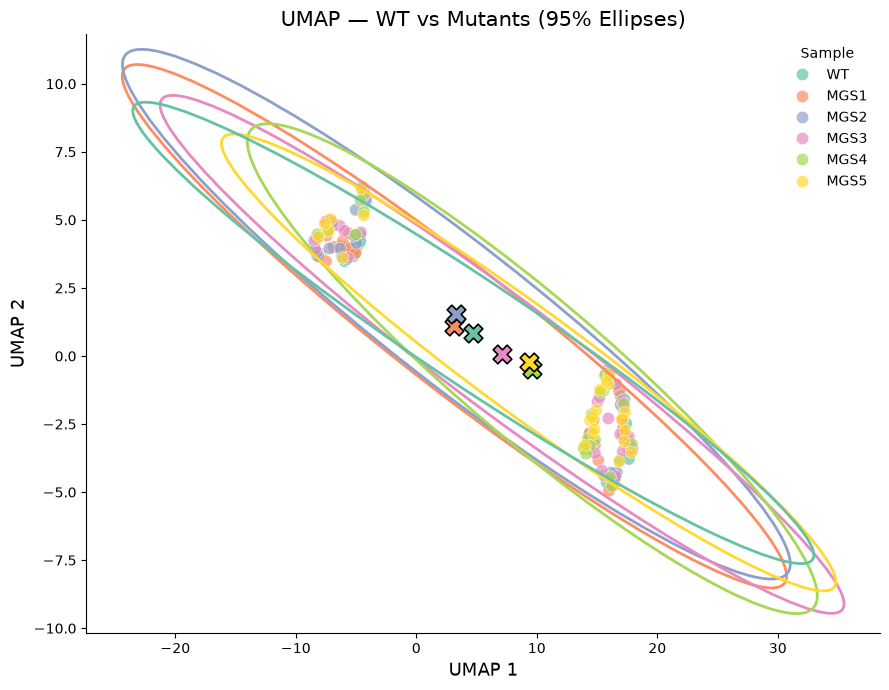

In [12]:
# Prepare data
plot_df = umap_df.dropna(
    subset=["UMAP1", "UMAP2", "sample"]
).copy()

# Consistent colors
samples = plot_df["sample"].unique()

palette = dict(zip(
    samples,
    sns.color_palette("Set2", n_colors=len(samples))
))

# Plot
fig, ax = plt.subplots(figsize=(9, 7))

sns.scatterplot(
    data=plot_df,
    x="UMAP1",
    y="UMAP2",
    hue="sample",
    palette=palette,
    s=80,
    alpha=0.7,
    edgecolor="white",
    linewidth=0.5,
    ax=ax
)

# Add ellipses and centroids
for group, data in plot_df.groupby("sample"):

    confidence_ellipse(
        data["UMAP1"],
        data["UMAP2"],
        ax=ax,
        confidence=0.95,
        edgecolor=palette[group]
    )

    ax.scatter(
        data["UMAP1"].mean(),
        data["UMAP2"].mean(),
        marker="X",
        s=180,
        color=palette[group],
        edgecolor="black",
        linewidth=1.2,
        zorder=5
    )

ax.set_xlabel("UMAP 1", fontsize=13)
ax.set_ylabel("UMAP 2", fontsize=13)
ax.set_title(
    "UMAP — WT vs Mutants (95% Ellipses)",
    fontsize=15
)

ax.legend(title="Sample", frameon=False)

sns.despine()
plt.tight_layout()
plt.show()

### Check the amount of clusters in UMAPs

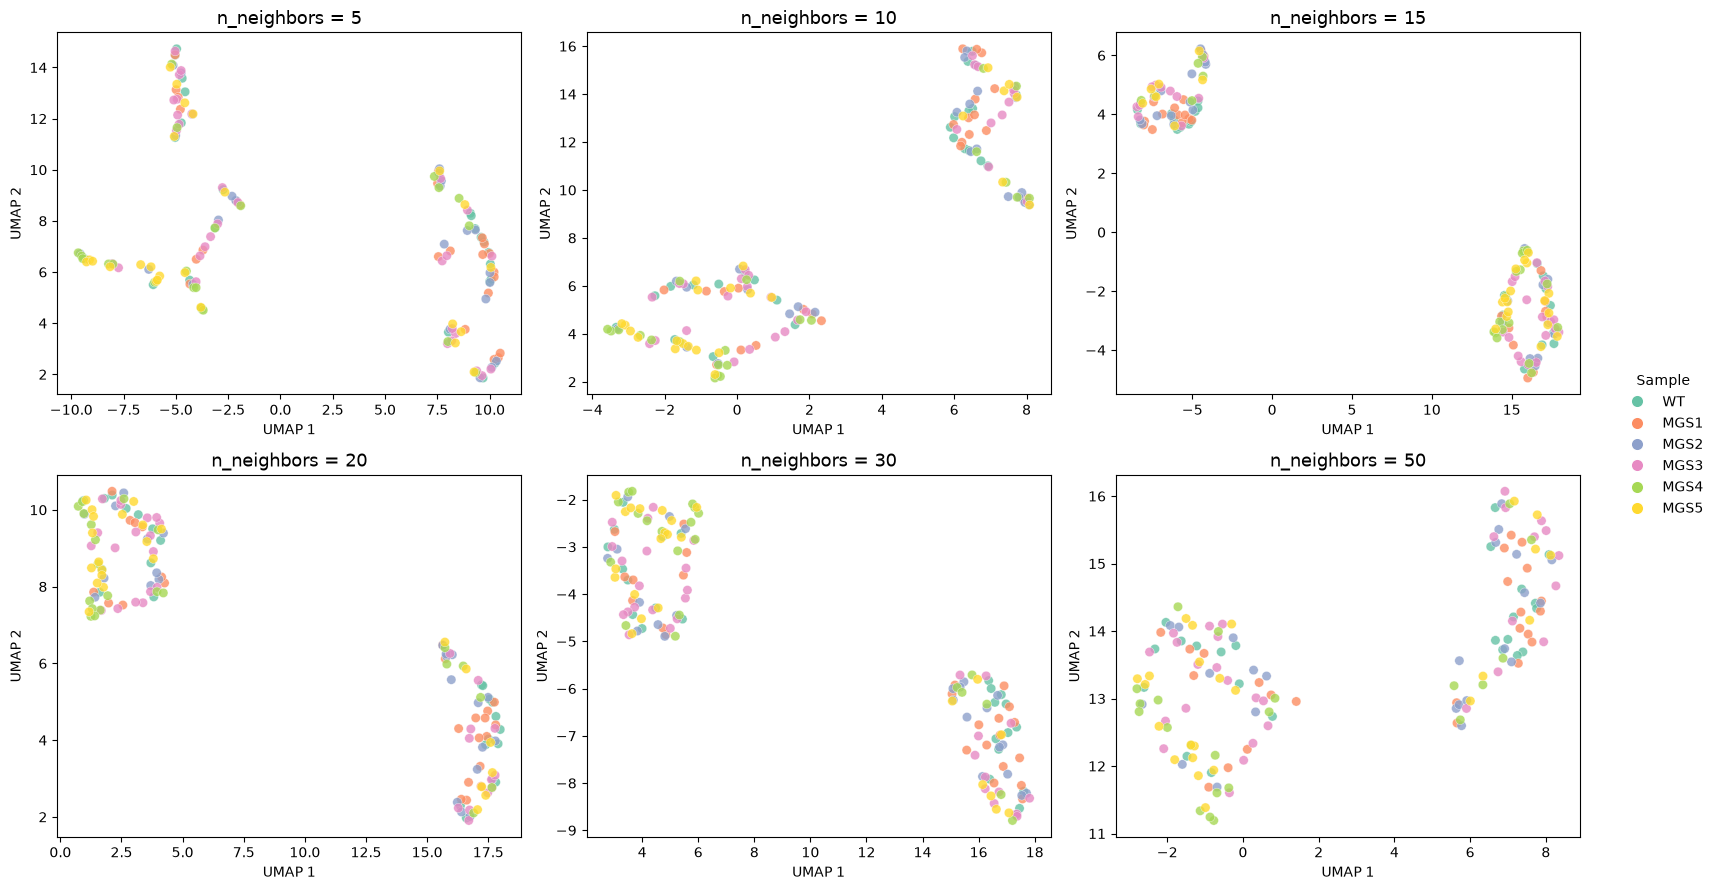

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

neighbors = [5, 10, 15, 20, 30, 50]

# Consistent colors for samples
samples = subset["sample"].unique()

palette = dict(zip(
    samples,
    sns.color_palette("Set2", len(samples))
))

for ax, n in zip(axes.flat, neighbors):

    reducer = umap.UMAP(
        n_neighbors=n,
        min_dist=0.1,
        random_state=42,
        n_jobs=1,
    )

    embedding = reducer.fit_transform(X_scaled)

    sns.scatterplot(
        x=embedding[:, 0],
        y=embedding[:, 1],
        hue=subset["sample"].to_numpy(),
        hue_order=samples,
        palette=palette,
        s=45,
        alpha=0.8,
        edgecolor="white",
        linewidth=0.3,
        legend=False,
        ax=ax
    )

    ax.set_title(f"n_neighbors = {n}", fontsize=13)
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")

# Create shared legend
from matplotlib.lines import Line2D

handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        label=sample,
        markerfacecolor=palette[sample],
        markeredgecolor="white",
        markersize=9
    )
    for sample in samples
]

fig.legend(
    handles=handles,
    title="Sample",
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    frameon=False
)

plt.tight_layout()
plt.show()

### Visualize each sample separately

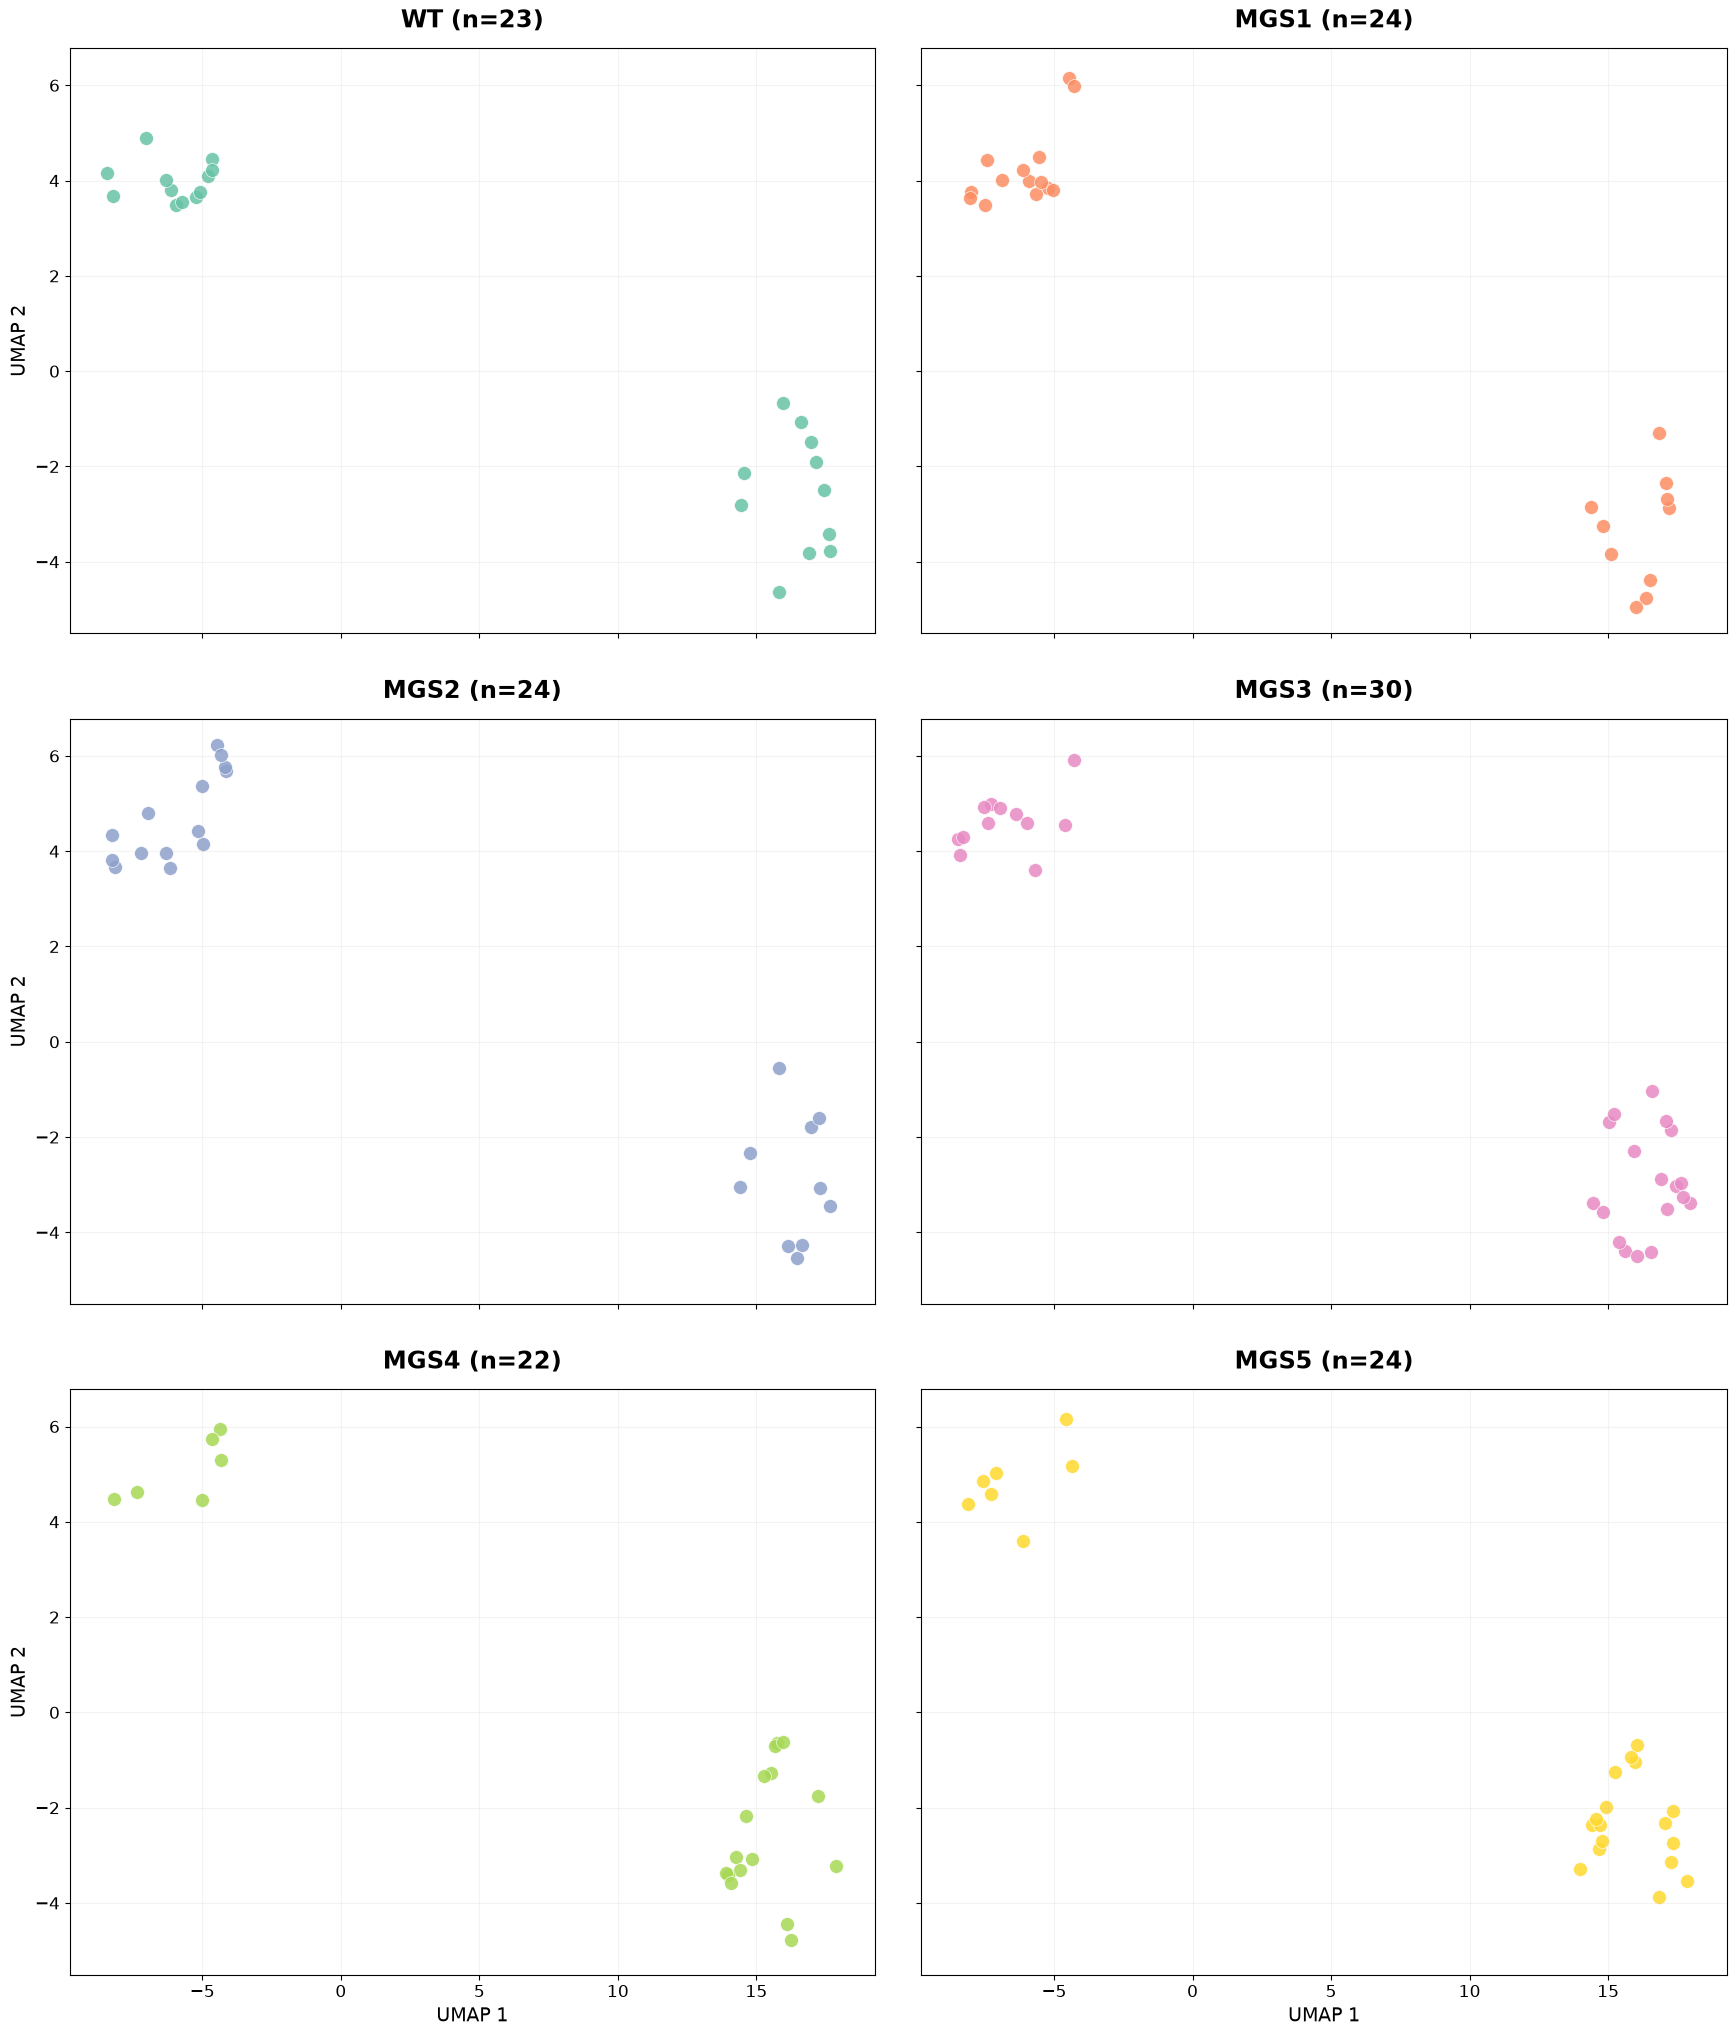

In [19]:
import math

groups = umap_df["sample"].dropna().unique()
n_groups = len(groups)

# Layout: 2 columns
ncols = min(2, n_groups)
nrows = math.ceil(n_groups / ncols)

# Consistent colors
palette = dict(zip(
    groups,
    sns.color_palette("Set2", n_groups)
))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(9 * ncols, 7 * nrows),
    sharex=True,
    sharey=True,
    squeeze=False
)

axes = axes.flatten()

# Consistent axis limits with padding
x_min, x_max = umap_df["UMAP1"].min(), umap_df["UMAP1"].max()
y_min, y_max = umap_df["UMAP2"].min(), umap_df["UMAP2"].max()

x_pad = (x_max - x_min) * 0.05
y_pad = (y_max - y_min) * 0.05

for ax, group in zip(axes, groups):

    subset = umap_df[umap_df["sample"] == group]

    sns.scatterplot(
        data=subset,
        x="UMAP1",
        y="UMAP2",
        color=palette[group],
        alpha=0.85,
        s=100,
        edgecolor="white",
        linewidth=0.5,
        ax=ax
    )

    ax.set_title(
        f"{group} (n={len(subset)})",
        fontsize=17,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("UMAP 1", fontsize=14)
    ax.set_ylabel("UMAP 2", fontsize=14)

    ax.set_xlim(x_min - x_pad, x_max + x_pad)
    ax.set_ylim(y_min - y_pad, y_max + y_pad)

    ax.tick_params(labelsize=12)
    ax.grid(alpha=0.15)

# Remove unused panels
for ax in axes[n_groups:]:
    ax.remove()

plt.tight_layout(pad=3)
plt.show()

### KMeans

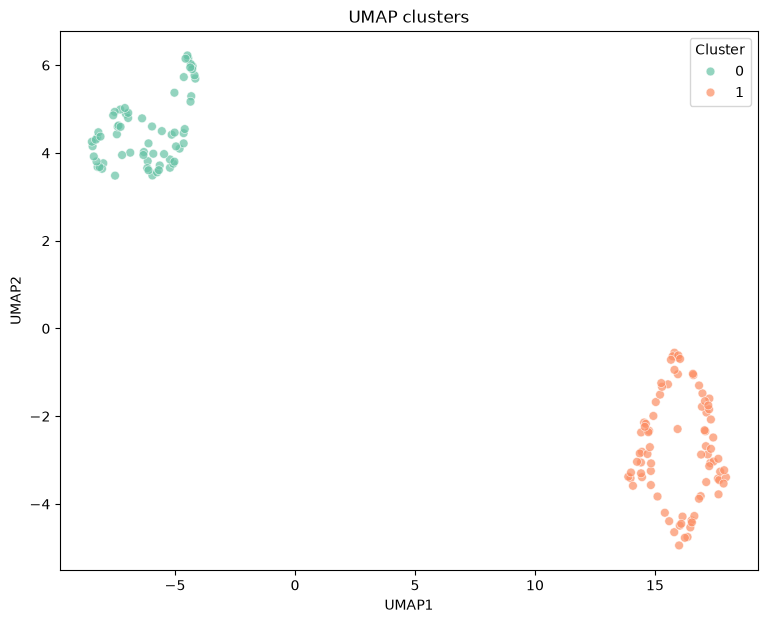

In [20]:
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

umap_df["cluster"] = kmeans.fit_predict(
    umap_df[["UMAP1", "UMAP2"]]
)

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="cluster",
    palette="Set2",
    s=40,
    alpha=0.7
)

plt.title("UMAP clusters")
plt.legend(title="Cluster")
plt.show()

## PERMANOVA for all clusters together

In [21]:
# Select features and groups
data = df[features + ["sample"]].dropna().copy()

X = data[features]
groups = data["sample"].to_numpy()

# Standardize features
X_scaled = StandardScaler().fit_transform(X)

# Euclidean distance matrix
distances = squareform(
    pdist(X_scaled, metric="euclidean")
)

dm = DistanceMatrix(distances)

# PERMANOVA
permanova_result = permanova(
    dm,
    grouping=groups,
    permutations=9999,
    seed=42
)

# PERMDISP
permdisp_result = permdisp(
    dm,
    grouping=groups,
    test="centroid",
    permutations=9999,
    seed=42
)

# Calculate R²
F = permanova_result["test statistic"]
n = len(groups)
k = len(np.unique(groups))

R2 = (F * (k - 1)) / (F * (k - 1) + (n - k))

# Results dataframe
results_df = pd.DataFrame({
    "Test": ["PERMANOVA", "PERMDISP"],
    "Statistic": [
        permanova_result["test statistic"],
        permdisp_result["test statistic"]
    ],
    "p_value": [
        permanova_result["p-value"],
        permdisp_result["p-value"]
    ],
    "R2": [R2, np.nan],
    "n": [n, n],
    "groups": [k, k]
})

display(results_df.round(4))

,Test,Statistic,p_value,R2,n,groups
0,PERMANOVA,0.8798,0.5542,0.0086,516,6
1,PERMDISP,2.5223,0.2456,NaN,516,6


## Cluster visualization separately for all samples

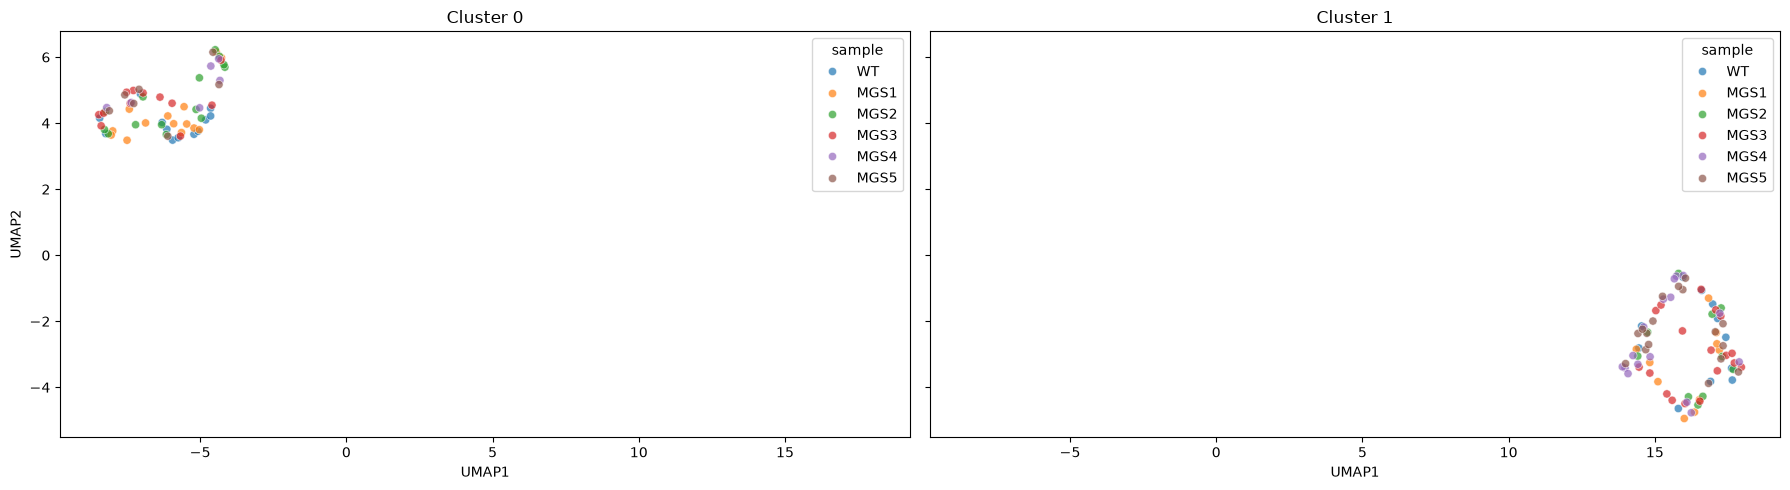

In [23]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

for cluster, ax in zip(sorted(umap_df["cluster"].unique()), axes):

    subset = umap_df[umap_df["cluster"] == cluster]

    sns.scatterplot(
        data=subset,
        x="UMAP1",
        y="UMAP2",
        hue="sample",
        palette="tab10",
        alpha=0.7,
        s=35,
        ax=ax
    )

    ax.set_title(f"Cluster {cluster}")

plt.tight_layout()
plt.show()

## Cells per cluster across all samples

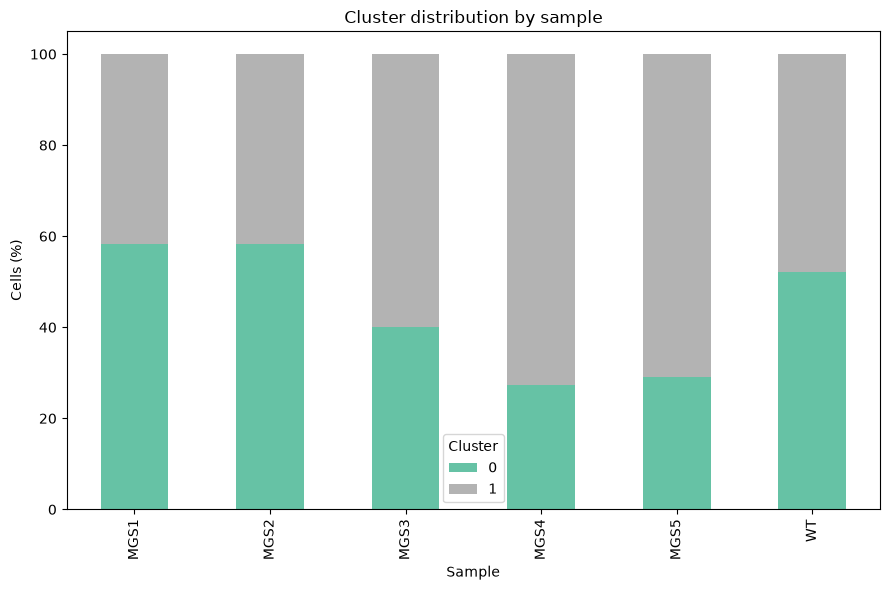

In [25]:
counts = pd.crosstab(
    umap_df["sample"],
    umap_df["cluster"]
)

proportions = counts.div(
    counts.sum(axis=1),
    axis=0
) * 100

#print(proportions.round(2))

proportions.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6),
    colormap="Set2"
)

plt.ylabel("Cells (%)")
plt.xlabel("Sample")
plt.title("Cluster distribution by sample")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## Statistics within each cluster for all samples

In [30]:
results = []

for cluster, subset in umap_df.groupby("cluster"):

    subset = subset.dropna(subset=features)

    if subset["sample"].nunique() < 2:
        continue

    X = StandardScaler().fit_transform(subset[features])

    distances = squareform(
        pdist(X, metric="euclidean")
    )

    dm = DistanceMatrix(
        distances,
        ids=[str(i) for i in range(len(subset))]
    )

    result = permanova(
        dm,
        grouping=subset["sample"].to_numpy(),
        permutations=9999
    )

    results.append({
        "cluster": cluster,
        "F": result["test statistic"],
        "p_value": result["p-value"],
        "n": len(subset)
    })

results_df = pd.DataFrame(results)
print(results_df)

   cluster         F  p_value   n
0        0  1.210394   0.2548  65
1        1  2.966435   0.0007  82


### 95% CI UMAP graph

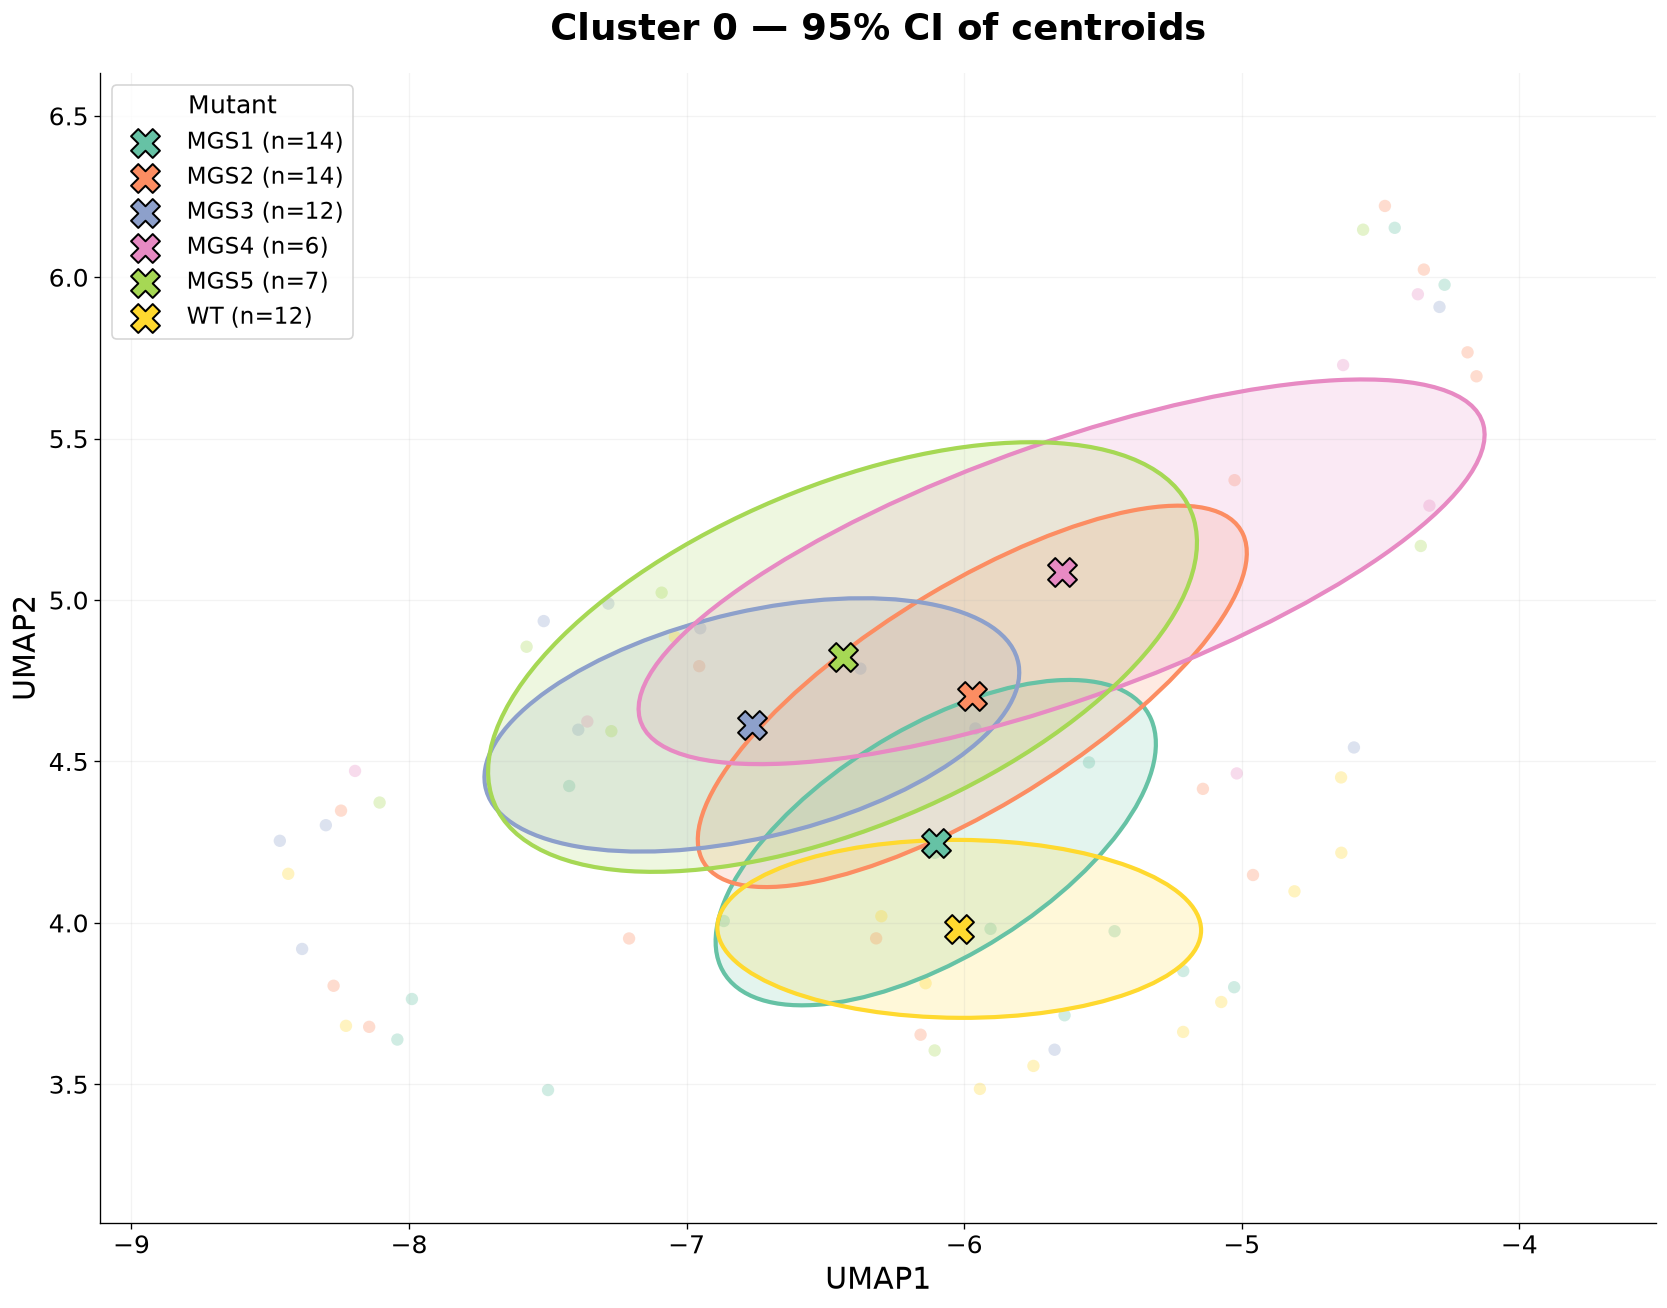

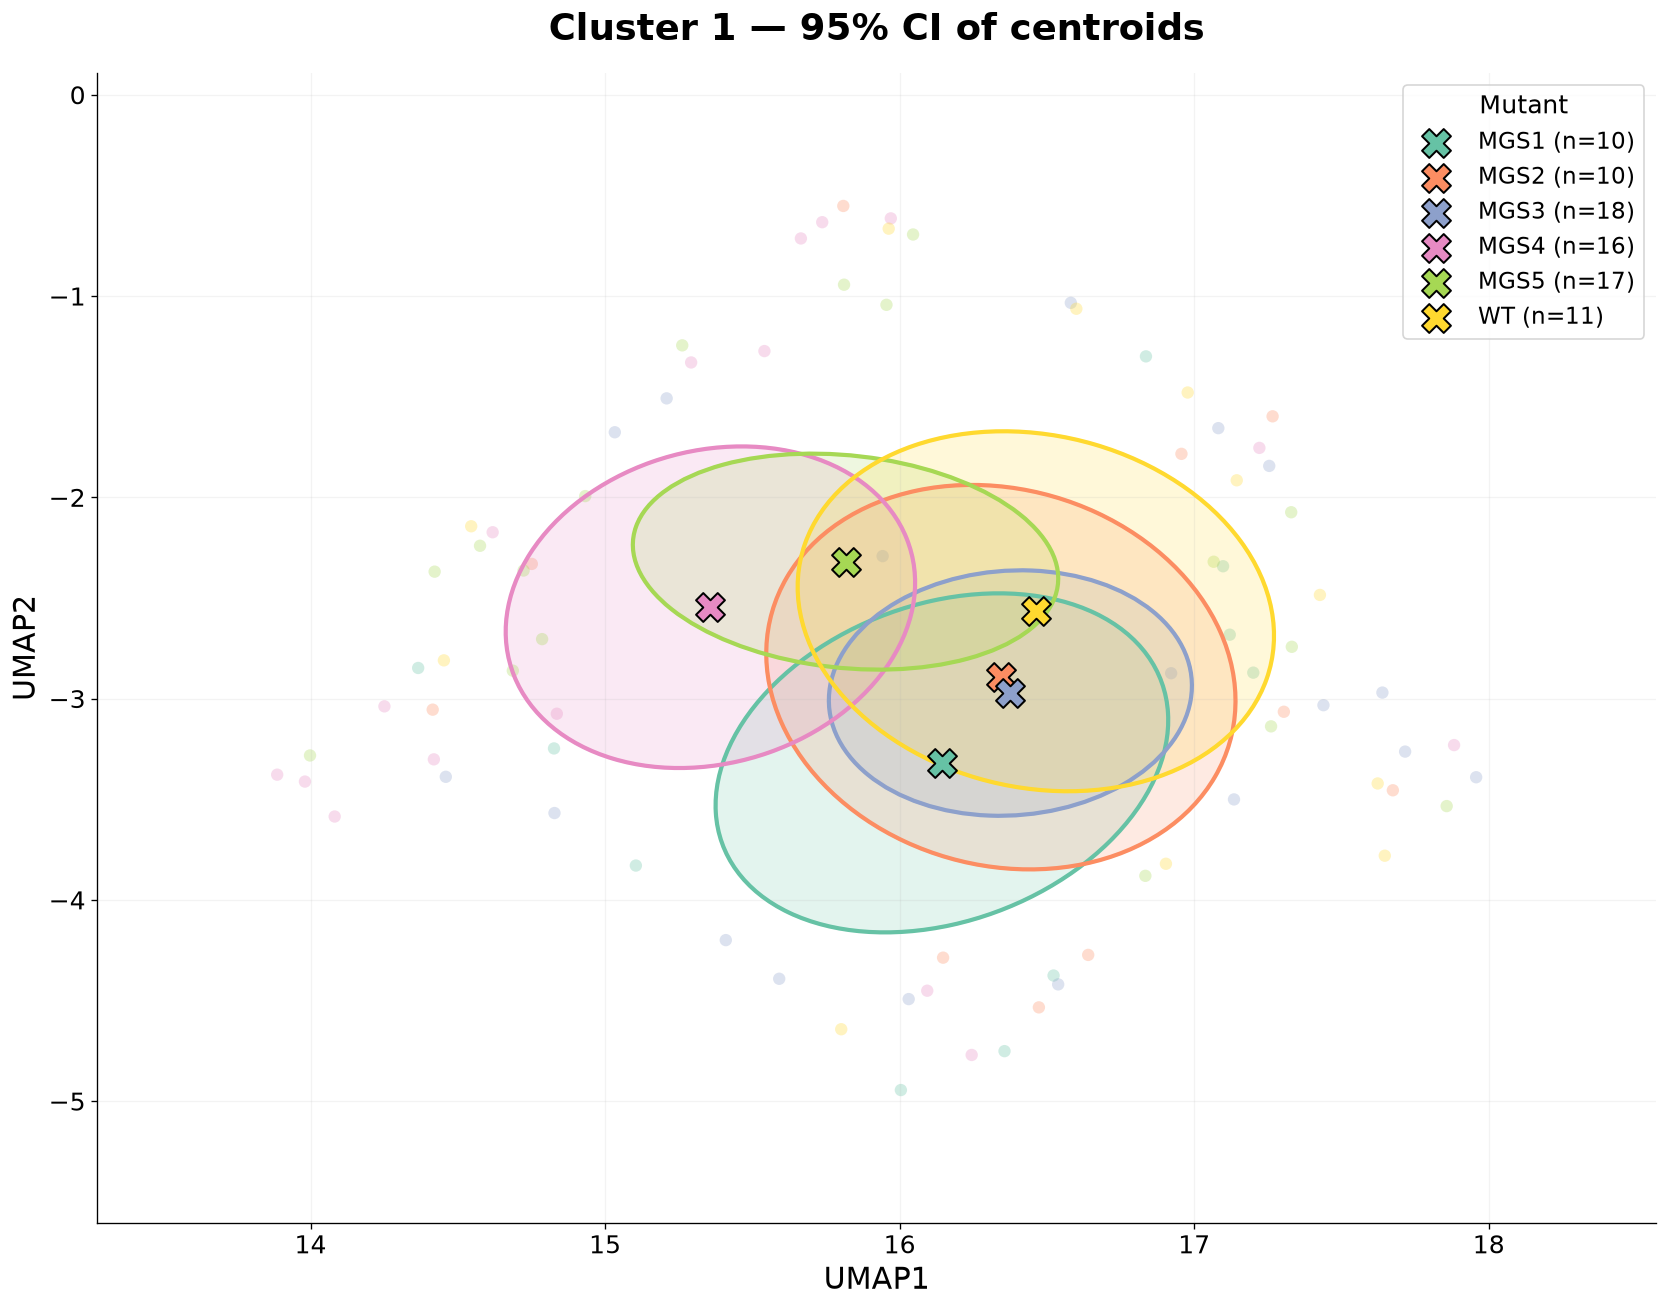

    cluster sample   n  centroid_x  centroid_y
0         0   MGS1  14   -6.102396    4.248593
1         0   MGS2  14   -5.970706    4.701736
2         0   MGS3  12   -6.764903    4.613333
3         0   MGS4   6   -5.648991    5.087595
4         0   MGS5   7   -6.438216    4.823605
5         0     WT  12   -6.017826    3.981508
6         1   MGS1  10   16.143482   -3.319277
7         1   MGS2  10   16.343685   -2.893518
8         1   MGS3  18   16.375956   -2.972465
9         1   MGS4  16   15.357548   -2.546033
10        1   MGS5  17   15.816309   -2.319516
11        1     WT  11   16.462345   -2.566113


In [35]:
def plot_cluster_centroids_ci(
    umap_df,
    cluster_col="cluster",
    group_col="sample",
    features=("UMAP1", "UMAP2"),
    n_boot=5000,
    confidence=0.95,
    random_state=42,
    show_points=True,
    figsize=(14, 11),
    point_size=55,
    centroid_size=300,
    zoom_padding=0.15
):

    rng = np.random.default_rng(random_state)

    df = umap_df.dropna(
        subset=[cluster_col, group_col, *features]
    ).copy()

    clusters = sorted(df[cluster_col].unique())
    groups = sorted(df[group_col].unique())

    # Consistent colors across clusters
    palette = dict(zip(
        groups,
        sns.color_palette("Set2", len(groups))
    ))

    centroid_results = []

    # ONE LARGE FIGURE PER CLUSTER
    for cluster in clusters:

        cluster_df = df[df[cluster_col] == cluster]

        fig, ax = plt.subplots(
            figsize=figsize,
            dpi=120
        )

        for group, subset in cluster_df.groupby(group_col):

            X = subset[list(features)].to_numpy()
            n = len(X)

            if n == 0:
                continue

            color = palette[group]

            # ---------------------------------
            # 1. Individual cells
            # ---------------------------------
            if show_points:
                ax.scatter(
                    X[:, 0],
                    X[:, 1],
                    s=point_size,
                    alpha=0.30,
                    color=color,
                    edgecolors="none",
                    zorder=1
                )

            # ---------------------------------
            # 2. Observed centroid
            # ---------------------------------
            centroid = X.mean(axis=0)

            # ---------------------------------
            # 3. Bootstrap 95% CI ellipse
            # ---------------------------------
            if n >= 3:

                boot_idx = rng.integers(
                    0,
                    n,
                    size=(n_boot, n)
                )

                boot_centroids = X[boot_idx].mean(axis=1)

                cov = np.cov(
                    boot_centroids,
                    rowvar=False
                )

                eigenvalues, eigenvectors = np.linalg.eigh(cov)

                order = eigenvalues.argsort()[::-1]
                eigenvalues = eigenvalues[order]
                eigenvectors = eigenvectors[:, order]

                scale = np.sqrt(
                    chi2.ppf(confidence, df=2)
                )

                width, height = (
                    2 * scale *
                    np.sqrt(np.maximum(eigenvalues, 0))
                )

                angle = np.degrees(
                    np.arctan2(
                        eigenvectors[1, 0],
                        eigenvectors[0, 0]
                    )
                )

                # Filled confidence ellipse
                ellipse = Ellipse(
                    xy=centroid,
                    width=width,
                    height=height,
                    angle=angle,
                    facecolor=color,
                    edgecolor=color,
                    alpha=0.18,
                    linewidth=2
                )

                ax.add_patch(ellipse)

                # Confidence ellipse outline
                outline = Ellipse(
                    xy=centroid,
                    width=width,
                    height=height,
                    angle=angle,
                    fill=False,
                    edgecolor=color,
                    linewidth=2.5,
                    zorder=3
                )

                ax.add_patch(outline)

            # ---------------------------------
            # 4. Centroid marker
            # ---------------------------------
            ax.scatter(
                centroid[0],
                centroid[1],
                s=centroid_size,
                marker="X",
                color=color,
                edgecolor="black",
                linewidth=1.2,
                zorder=5,
                label=f"{group} (n={n})"
            )

            centroid_results.append({
                "cluster": cluster,
                "sample": group,
                "n": n,
                "centroid_x": centroid[0],
                "centroid_y": centroid[1]
            })

        # ---------------------------------
        # 5. Formatting
        # ---------------------------------
        ax.set_title(
            f"Cluster {cluster} — 95% CI of centroids",
            fontsize=22,
            fontweight="bold",
            pad=20
        )

        ax.set_xlabel(features[0], fontsize=18)
        ax.set_ylabel(features[1], fontsize=18)

        ax.tick_params(labelsize=15)

        ax.legend(
            title="Mutant",
            fontsize=14,
            title_fontsize=15,
            loc="best",
            frameon=True
        )

        ax.grid(alpha=0.15)

        ax.spines[["top", "right"]].set_visible(False)

        # ---------------------------------
        # 6. Zoom to individual cluster
        # ---------------------------------
        x = cluster_df[features[0]]
        y = cluster_df[features[1]]

        x_range = x.max() - x.min()
        y_range = y.max() - y.min()

        x_pad = max(x_range * zoom_padding, 0.1)
        y_pad = max(y_range * zoom_padding, 0.1)

        ax.set_xlim(
            x.min() - x_pad,
            x.max() + x_pad
        )

        ax.set_ylim(
            y.min() - y_pad,
            y.max() + y_pad
        )

        plt.tight_layout()
        plt.show()

    return pd.DataFrame(centroid_results)


# RUN
centroid_df = plot_cluster_centroids_ci(
    umap_df,
    cluster_col="cluster",
    group_col="sample",
    features=("UMAP1", "UMAP2"),
    n_boot=5000,
    confidence=0.95,
    figsize=(14, 11),
    point_size=55,
    centroid_size=300,
    zoom_padding=0.15,
    show_points=True
)

print(centroid_df)

### Centroid distance visualization for each cluster separately

   cluster sample  distance   n
0        0   MGS1  1.186483  14
1        0   MGS2  2.339846  14
2        0   MGS3  0.849712  12
3        0   MGS4  3.066291   6
4        0   MGS5  1.578654   7
5        1   MGS1  0.482858  10
6        1   MGS2  0.219905  10
7        1   MGS3  0.322465  18
8        1   MGS4  0.648084  16
9        1   MGS5  0.303521  17


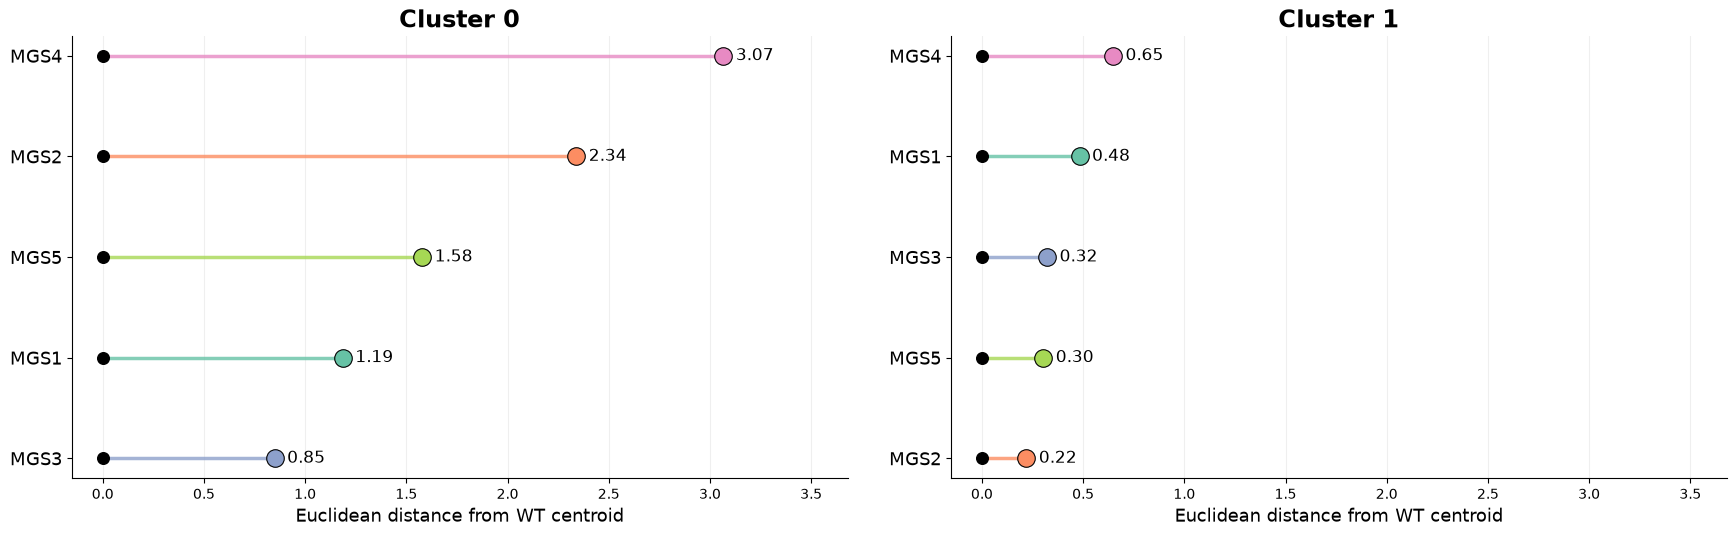

In [33]:
# Settings
reference = "WT"
group_col = "sample"
cluster_col = "cluster"

# Use the same features as in your PERMANOVA
# features = [...]

# Keep only valid rows
df = umap_df.dropna(
    subset=features + [group_col, cluster_col]
).copy()

# Standardize features globally
# This makes distances comparable between clusters
scaler = StandardScaler()
df[features] = scaler.fit_transform(df[features])

# Consistent colors for mutants
groups = sorted(df[group_col].unique())

palette = dict(zip(
    groups,
    sns.color_palette("Set2", len(groups))
))

# Calculate centroid distances
distance_results = []

for cluster, subset in df.groupby(cluster_col):

    if reference not in subset[group_col].values:
        continue

    # Centroid of each sample
    centroids = subset.groupby(group_col)[features].mean()

    # WT centroid
    ref_centroid = centroids.loc[reference].values

    for group in centroids.index:

        if group == reference:
            continue

        distance = np.linalg.norm(
            centroids.loc[group].values - ref_centroid
        )

        distance_results.append({
            "cluster": cluster,
            "sample": group,
            "distance": distance,
            "n": (subset[group_col] == group).sum()
        })

distance_df = pd.DataFrame(distance_results)

print(distance_df)

# Plot centroid distance trees
clusters = sorted(distance_df["cluster"].unique())

ncols = min(2, len(clusters))
nrows = math.ceil(len(clusters) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(9 * ncols, 6 * nrows),
    squeeze=False
)

axes = axes.flatten()

max_distance = distance_df["distance"].max()

for ax, cluster in zip(axes, clusters):

    data = distance_df[
        distance_df["cluster"] == cluster
    ].sort_values("distance")

    y_positions = np.arange(len(data))

    for y, (_, row) in zip(y_positions, data.iterrows()):

        group = row["sample"]
        distance = row["distance"]

        # Line from WT to mutant centroid
        ax.plot(
            [0, distance],
            [y, y],
            color=palette[group],
            linewidth=2.5,
            alpha=0.8
        )

        # WT reference
        ax.scatter(
            0, y,
            color="black",
            s=70,
            zorder=3
        )

        # Mutant centroid
        ax.scatter(
            distance, y,
            color=palette[group],
            s=160,
            edgecolor="black",
            linewidth=0.8,
            zorder=4
        )

        # Distance label
        ax.text(
            distance + max_distance * 0.02,
            y,
            f"{distance:.2f}",
            va="center",
            fontsize=12
        )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        data["sample"],
        fontsize=13
    )

    ax.set_xlim(
        -max_distance * 0.05,
        max_distance * 1.20
    )

    ax.set_xlabel(
        "Euclidean distance from WT centroid",
        fontsize=13
    )

    ax.set_title(
        f"Cluster {cluster}",
        fontsize=17,
        fontweight="bold"
    )

    ax.grid(
        axis="x",
        alpha=0.2
    )

    ax.spines[["top", "right"]].set_visible(False)

# Remove empty subplots
for ax in axes[len(clusters):]:
    ax.remove()

plt.tight_layout(pad=3)
plt.show()

## List of samples from different clusters

In [44]:
cluster = 0

for image_id in df.loc[df["cluster"] == cluster, "image_id"]:
    print(image_id)

C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series_01)_ROI_0250-0321
C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series_02)_ROI_0190-0261
C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series_06)_ROI_0278-0248
C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series_07)_ROI_0249-0247
C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series_09)_ROI_0251-0280
C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series_17)_ROI_0217-0275
C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series_18)_ROI_0216-0254
C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series_19)_ROI_0206-0216
C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series_20)_ROI_0208-0237
C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series_21)_ROI_0244-0259
C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series_22)_ROI_0267-0231
C2_MP_U2OS_fixed_20nMJF549_ORC1_WT.nd2_(series_23)_ROI_0269-0245
C2_MP_U2OS_fixed_20nMJF549_ORC1_MGS1.nd2_(series_01)_ROI_0195-0258
C2_MP_U2OS_fixed_20nMJF549_ORC1_MGS1.nd2_(series_02)_ROI_0224-0230
C2_MP_U2OS_fixed_20nMJF549_ORC1_MGS1.nd2_(series_04)_ROI_0239-0261
C2_MP_U2OS_fixed_20

## Difference between clusters

In [53]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from sklearn.preprocessing import StandardScaler


features = [
    "n_foci",
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
    "min_intensity",
]


# Keep only the two clusters
clusters = sorted(umap_df["cluster"].dropna().unique())

assert len(clusters) == 2, "Expected exactly two clusters"

df_analysis = umap_df.dropna(
    subset=["cluster"] + features
).copy()

# Summary statistics
summary = df_analysis.groupby("cluster")[features].agg(
    ["median", "std", "count"]
)

#display(summary.round(3))

results = []

c0, c1 = clusters

for feature in features:

    x = df_analysis.loc[
        df_analysis["cluster"] == c0, feature
    ].dropna()

    y = df_analysis.loc[
        df_analysis["cluster"] == c1, feature
    ].dropna()

    # Cohen's d
    pooled_sd = np.sqrt(
        ((len(x)-1)*x.var(ddof=1) +
         (len(y)-1)*y.var(ddof=1)) /
        (len(x)+len(y)-2)
    )

    d = (
        (y.median() - x.median()) / pooled_sd
        if pooled_sd > 0 else np.nan
    )

    # Mann–Whitney U
    stat, p = mannwhitneyu(
        x, y,
        alternative="two-sided"
    )

    results.append({
        "feature": feature,
        f"mean_cluster_{c0}": x.mean(),
        f"mean_cluster_{c1}": y.mean(),
        "cohens_d": d,
        "abs_effect_size": abs(d),
        "p_value": p
    })

results_df = pd.DataFrame(results)

# Multiple-testing correction
results_df["p_adjusted"] = multipletests(
    results_df["p_value"],
    method="fdr_bh"
)[1]

results_df = results_df.sort_values(
    "abs_effect_size",
    ascending=False
)

display(results_df.round(2))

,feature,mean_cluster_0,mean_cluster_1,cohens_d,abs_effect_size,p_value,p_adjusted
5,solidity,0.92,1.00,2.47,2.47,0.0,0.0
0,n_foci,230.60,371.10,0.83,0.83,0.0,0.0
4,perimeter,6.75,4.44,-0.65,0.65,0.0,0.0
3,eccentricity,0.79,0.87,0.50,0.50,0.0,0.0
2,equivalent_diameter_area,2.99,2.38,-0.48,0.48,0.0,0.0
1,area,7.42,4.48,-0.32,0.32,0.0,0.0
7,max_intensity,181.68,39.76,-0.18,0.18,0.0,0.0
6,mean_intensity,162.20,35.50,-0.17,0.17,0.0,0.0
8,min_intensity,145.37,31.51,-0.16,0.16,0.0,0.0
